# Experiment 5 — Temperature + Humidity + Historical Wind + Solar

This experiment tests whether adding genuinely new environmental information improves
thermal-sensation prediction.

**Features**
- `temperature_c`
- `relative_humidity`
- `wind_speed_10m_ms`
- `shortwave_radiation_wm2`

The target remains the same 3-class thermal sensation label.

## Modelling rules used in this notebook

- Target:
  - `0 = Not warm / OK`
  - `1 = Warm`
  - `2 = Too hot`
- Primary metric: **Macro-F1**
- Also report:
  - Balanced Accuracy
  - Ordinal MAE
  - Multiclass Brier score
  - Per-class precision/recall/F1
  - Confusion matrix
- Model selection is based on **training cross-validation**, not the held-out test result.
- The final test set is used only for confirmation.
- `city` is used for stratification/evaluation, not as a predictive feature.

In [1]:
from pathlib import Path  # File and folder paths
import json
import warnings

import joblib  # Load and save model artifacts
import numpy as np  # Numerical operations
import pandas as pd  # Data handling
import matplotlib.pyplot as plt  # Plotting

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from statsmodels.miscmodels.ordinal_model import OrderedModel

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

RANDOM_STATE = 42  # Keep results reproducible
TEST_SIZE = 0.20  # Proportion reserved for final test
CV_FOLDS = 5  # Number of cross-validation folds

CLASS_NAMES = ["Not warm / OK", "Warm", "Too hot"]

print("XGBoost available:", XGBOOST_AVAILABLE)

XGBoost available: False


In [2]:
# ------------------------------------------------------------
# LOAD THE PREPARED THERMAL DATASET
# ------------------------------------------------------------
# find_processed_file() searches several possible project folders
# so the notebook can still find the prepared CSV when it is run
# from different working directories.
#
# DATA_PATH points to the prepared Thermosurvey dataset.
# RESULTS_DIR and ARTIFACTS_DIR are created if they do not exist.
# pd.read_csv() loads the prepared dataset into a pandas DataFrame.
# ------------------------------------------------------------
def find_processed_file(filename):
    cwd = Path.cwd().resolve()

    candidates = []

    # Works if notebook is run from ai/thermal_model/models/
    # or from ai/thermal_model/, repository root, etc.
    for base in [cwd, *cwd.parents]:
        candidates.extend([
            base / "data" / "processed" / filename,
            base / "ai" / "thermal_model" / "data" / "processed" / filename,
        ])

    for path in candidates:
        if path.exists():
            return path.resolve()

    raise FileNotFoundError(
        f"Could not find {filename}. "
        "Expected it under ai/thermal_model/data/processed/."
    )

DATA_PATH = find_processed_file("thermosurvey_extended_prepared.csv")
THERMAL_MODEL_DIR = DATA_PATH.parents[2]

RESULTS_DIR = THERMAL_MODEL_DIR / "results"
ARTIFACTS_DIR = THERMAL_MODEL_DIR / "artifacts"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)  # Load prepared dataset

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("Thermal model directory:", THERMAL_MODEL_DIR)

Dataset: ai/thermal_model\data\processed\thermosurvey_extended_prepared.csv
Shape: (2099, 19)
Thermal model directory: ai/thermal_model


## Historical weather enrichment

The original Thermosurvey CSV has measured temperature and humidity but does not contain
the wind speed and solar radiation needed by this experiment.

This notebook retrieves **hourly historical reanalysis** from Open-Meteo using the
participant's city and thermal-measurement timestamp.

Important limitation: only the city is available here, so city-centre coordinates are used.
The retrieved wind/solar values are therefore approximate environmental context, not
on-site measurements at the participant's exact interview position.

The weather cache is saved as:

`data/processed/thermosurvey_historical_weather_enriched.csv`

so Experiment 5 and Experiment 6 can reuse the same enrichment.

In [ ]:
# ------------------------------------------------------------
# ADD HISTORICAL WIND AND SOLAR-RADIATION DATA
# ------------------------------------------------------------
# This section uses the Open-Meteo historical archive API.
#
# CITY_CONFIG stores coordinates and time zones for Warsaw and Madrid.
# fetch_city_weather() downloads hourly wind speed and shortwave
# radiation for one city.
#
# build_weather_enrichment() combines the downloaded weather data
# with each Thermosurvey record using city and nearest local hour.
#
# WEATHER_CACHE avoids downloading the same historical weather every
# time the notebook is run. If a valid cached CSV exists, it is loaded;
# otherwise, the weather data is fetched and saved.
# ------------------------------------------------------------

# Used to send HTTP requests to the Open-Meteo API.
import requests


# Define where the weather-enriched dataset will be saved.
WEATHER_CACHE = (
    THERMAL_MODEL_DIR
    / "data"
    / "processed"
    / "thermosurvey_historical_weather_enriched.csv"
)


# Store the coordinates and timezone for each city in the dataset.
# These values are needed when requesting historical weather.
CITY_CONFIG = {
    "Warsaw": {
        "latitude": 52.2297,
        "longitude": 21.0122,
        "timezone": "Europe/Warsaw",
    },
    "Madrid": {
        "latitude": 40.4168,
        "longitude": -3.7038,
        "timezone": "Europe/Madrid",
    },
}


# Historical weather API endpoint.
OPEN_METEO_ARCHIVE_URL = (
    "https://archive-api.open-meteo.com/v1/archive"
)


# Download historical weather for one city.
def fetch_city_weather(city, city_rows):

    # Make sure the city has coordinates defined above.
    if city not in CITY_CONFIG:
        raise ValueError(f"No coordinate configuration for city: {city}")

    # Get this city's latitude, longitude and timezone.
    cfg = CITY_CONFIG[city]

    # Convert the survey timestamps into pandas datetime format.
    datetimes = pd.to_datetime(
        city_rows["thermal_datetime_local"],
        errors="coerce",
    )

    # Check whether any timestamp could not be converted.
    if datetimes.isna().any():
        raise ValueError(
            f"{city}: thermal_datetime_local contains invalid timestamps."
        )

    # Find the earliest survey date for this city.
    start_date = datetimes.min().date()

    # Find the latest survey date.
    # Add one extra day because rounding to the nearest hour
    # may move a late-night record into the next day.
    end_date = (
        datetimes.max().normalize()
        + pd.Timedelta(days=1)
    ).date()

    # Build the parameters that will be sent to Open-Meteo.
    params = {
        "latitude": cfg["latitude"],
        "longitude": cfg["longitude"],
        "start_date": str(start_date),
        "end_date": str(end_date),

        # Request the two extra weather variables needed by Experiment 5.
        "hourly": "wind_speed_10m,shortwave_radiation",

        # Request wind speed in metres per second.
        "wind_speed_unit": "ms",

        # Ask Open-Meteo to return local time for the city.
        "timezone": cfg["timezone"],
    }

    # Show which city and date range are currently being downloaded.
    print(
        f"Fetching {city}: {start_date} to {end_date}"
    )

    # Send a GET request to the Open-Meteo historical weather API.
    response = requests.get(
        OPEN_METEO_ARCHIVE_URL,
        params=params,
        timeout=90,
    )

    # Stop if the API returned an unsuccessful HTTP status.
    response.raise_for_status()

    # Convert the JSON response into a Python dictionary.
    payload = response.json()

    # Check whether Open-Meteo returned its own error message.
    if payload.get("error"):
        raise RuntimeError(payload.get("reason", payload))

    # Get only the hourly weather section.
    # If it does not exist, use an empty dictionary.
    hourly = payload.get("hourly", {})

    # These are the fields that must exist in the API response.
    required_weather_keys = [
        "time",
        "wind_speed_10m",
        "shortwave_radiation",
    ]

    # Loop through every required field.
    # Keep only the fields that are missing from the API response.
    missing_keys = [
        key
        for key in required_weather_keys
        if key not in hourly
    ]

    # Stop if any required weather field is missing.
    if missing_keys:
        raise KeyError(
            f"{city}: Open-Meteo response missing {missing_keys}"
        )

    # Convert the hourly API data into a pandas DataFrame.
    weather = pd.DataFrame({
        "weather_hour_local": pd.to_datetime(hourly["time"]),
        "wind_speed_10m_ms": hourly["wind_speed_10m"],
        "shortwave_radiation_wm2": hourly["shortwave_radiation"],
    })

    # Add the city name to every weather row.
    # This is needed later when joining weather to the survey records.
    weather["city"] = city

    # Return the weather table for this city.
    return weather


# Add historical weather information to the original survey dataset.
def build_weather_enrichment(source_df):

    # Create an empty list to store weather DataFrames
    # from each city.
    frames = []

    # Group the survey records by city.
    # The loop runs once for Warsaw and once for Madrid.
    for city, city_rows in source_df.groupby("city"):

        # Download historical weather for this city
        # and add the resulting DataFrame to the list.
        frames.append(
            fetch_city_weather(
                city,
                city_rows,
            )
        )

    # Combine the separate Warsaw and Madrid weather tables
    # into one DataFrame.
    weather_df = pd.concat(
        frames,
        ignore_index=True,
    )

    # Make a copy so the original source DataFrame is not modified.
    enriched = source_df.copy()

    # Convert survey timestamps to datetime,
    # then round them to the nearest hour.
    #
    # This allows the survey timestamp to match the hourly
    # Open-Meteo weather data.
    enriched["weather_hour_local"] = (
        pd.to_datetime(
            enriched["thermal_datetime_local"],
            errors="coerce",
        )
        .dt.round("h")
    )

    # Join the historical weather data to the survey records.
    #
    # A row is matched using:
    # 1. city
    # 2. rounded local hour
    enriched = enriched.merge(
        weather_df,
        on=["city", "weather_hour_local"],

        # Keep every original survey record even if weather is missing.
        how="left",

        # Check that many survey records may match one weather-hour record.
        validate="many_to_one",
    )

    # Return the enriched Thermosurvey dataset.
    return enriched


# Check whether the enriched weather file has already been created.
if WEATHER_CACHE.exists():

    # If it exists, load it instead of calling the API again.
    print("Loading cached weather enrichment:")
    print(WEATHER_CACHE)

    enriched_df = pd.read_csv(WEATHER_CACHE)

    # Define the columns that must exist in a valid cached dataset.
    cache_required = {
        "wind_speed_10m_ms",
        "shortwave_radiation_wm2",
    }

    # Check whether both required weather columns exist.
    if not cache_required.issubset(enriched_df.columns):

        # If the cache is incomplete, download and rebuild the weather data.
        print("Existing cache is incomplete; rebuilding it.")

        enriched_df = build_weather_enrichment(df)

        # Save the rebuilt dataset.
        enriched_df.to_csv(
            WEATHER_CACHE,
            index=False,
            encoding="utf-8",
        )

else:
    # If no cached file exists, download the weather data.
    enriched_df = build_weather_enrichment(df)

    # Save the enriched dataset so the API does not need
    # to be called again next time.
    enriched_df.to_csv(
        WEATHER_CACHE,
        index=False,
        encoding="utf-8",
    )

    print("Saved weather enrichment:", WEATHER_CACHE)


# Show the final number of rows and columns.
print("\nWeather-enriched shape:", enriched_df.shape)


# Check whether any weather values are still missing.
print("\nMissing weather values:")

print(
    enriched_df[
        [
            "wind_speed_10m_ms",
            "shortwave_radiation_wm2",
        ]
    ]
    # Mark missing values as True/False.
    .isna()
    # Count the number of missing values in each column.
    .sum()
)


# Display the first 10 enriched records
# so we can manually inspect whether the merge worked correctly.
display(
    enriched_df[
        [
            "nr",
            "city",
            "thermal_datetime_local",
            "weather_hour_local",
            "temperature_c",
            "relative_humidity",
            "wind_speed_10m_ms",
            "shortwave_radiation_wm2",
        ]
    ].head(10)
)

Loading cached weather enrichment:
ai/thermal_model\data\processed\thermosurvey_historical_weather_enriched.csv

Weather-enriched shape: (2099, 22)

Missing weather values:
wind_speed_10m_ms          0
shortwave_radiation_wm2    0
dtype: int64


,nr,city,thermal_datetime_local,weather_hour_local,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2
0,4,Warsaw,2022-07-07 13:27:22,2022-07-07 13:00:00,27.5,29.6,3.77,660.0
1,5,Warsaw,2022-07-07 14:27:46,2022-07-07 14:00:00,23.5,37.7,2.39,371.0
2,8,Warsaw,2022-07-07 16:21:30,2022-07-07 16:00:00,23.9,53.5,1.91,282.0
3,9,Warsaw,2022-07-07 16:28:03,2022-07-07 16:00:00,27.8,36.6,1.91,282.0
4,10,Warsaw,2022-07-07 17:10:15,2022-07-07 17:00:00,27.8,36.6,1.66,185.0
5,24,Warsaw,2022-07-08 13:25:33,2022-07-08 13:00:00,27.2,57.6,3.40,339.0
6,25,Warsaw,2022-07-08 14:20:11,2022-07-08 14:00:00,27.1,51.7,1.43,562.0
7,27,Warsaw,2022-07-08 15:36:52,2022-07-08 16:00:00,25.0,70.8,4.95,381.0
8,47,Warsaw,2022-07-09 14:14:43,2022-07-09 14:00:00,20.9,51.8,4.63,526.0
9,53,Warsaw,2022-07-09 15:23:38,2022-07-09 15:00:00,22.1,50.2,5.48,544.0


In [ ]:
# ------------------------------------------------------------
# DEFINE EXPERIMENT 5 FEATURES AND FILTER THE DATA
# ------------------------------------------------------------
# Experiment 5 uses four prediction features:
# temperature, relative humidity, wind speed, and shortwave radiation.
#
# Only outdoor or semi-outdoor observations are retained.
# Rows missing a required feature, target class, or city are removed.
#
# The final lines display the feature summary and target distribution.
# ------------------------------------------------------------

# Define the four input features used by Experiment 5.
FEATURES = [
    "temperature_c",
    "relative_humidity",
    "wind_speed_10m_ms",
    "shortwave_radiation_wm2",
]

# Keep only outdoor or semi-outdoor survey records.
experiment_df = enriched_df[
    enriched_df["is_outdoor_or_semi"] == 1
].copy()

# Remove rows that are missing any required model feature,
# the target thermal class, or the city.
experiment_df = experiment_df.dropna(
    subset=FEATURES + ["thermal_class_code", "city"]
).copy()

# Show how many usable rows remain after filtering.
print("Experiment 5 rows:", len(experiment_df))

# Show summary statistics for the four model features.
print("\nFeature summary:")
display(experiment_df[FEATURES].describe())

# Show how many records belong to each thermal class.
print("\nTarget distribution:")
print(experiment_df["thermal_class_code"].value_counts().sort_index())

Experiment 5 rows: 689

Feature summary:


,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2
count,689.000000,689.000000,689.000000,689.000000
mean,29.119884,39.373149,3.055878,448.078374
std,4.212867,13.192482,1.482110,261.718504
min,17.000000,12.000000,0.280000,0.000000
25%,26.300000,28.200000,2.000000,231.000000
50%,29.200000,38.400000,2.910000,467.000000
75%,32.000000,50.200000,3.910000,672.000000
max,39.700000,87.200000,8.410000,947.000000



Target distribution:
thermal_class_code
0    246
1    230
2    213
Name: count, dtype: int64


In [ ]:
# ------------------------------------------------------------
# CREATE TRAINING AND HELD-OUT TEST SETS
# ------------------------------------------------------------
# A combined city + thermal-class key is created for stratification.
# This helps preserve both city and target-class proportions in the
# training and test sets.
#
# train_test_split() reserves TEST_SIZE of the data as the final test
# set. RANDOM_STATE makes the split reproducible.
#
# The printed tables verify class and city distributions after splitting.
# ------------------------------------------------------------

# Make a copy of the cleaned Experiment 5 dataset.
# This copy will be used for the train/test split.
split_df = experiment_df.copy()

# Create one combined label using both city and thermal class.
# Example:
# Warsaw + class 0  -> "Warsaw_0"
# Madrid + class 2  -> "Madrid_2"
#
# This is used so the train/test split keeps a similar
# proportion of both city and thermal classes.
split_df["stratify_key"] = (
    split_df["city"].astype(str)
    + "_"
    + split_df["thermal_class_code"].astype(str)
)

# Split the dataset into training and test sets.
train_df, test_df = train_test_split(
    split_df,

    # Percentage of rows used for the final test set.
    test_size=TEST_SIZE,

    # Keep the split reproducible.
    random_state=RANDOM_STATE,

    # Preserve the city + class proportions in both sets.
    stratify=split_df["stratify_key"],
)

# Show the total number of rows before splitting.
print("Experiment rows:", len(split_df))

# Show how many rows are in the training set.
print("Training rows:", len(train_df))

# Show how many rows are in the test set.
print("Test rows:", len(test_df))

# Count how many records of each thermal class
# are in the training set.
print("\nTraining class distribution:")
print(train_df["thermal_class_code"].value_counts().sort_index())

# Count how many records of each thermal class
# are in the test set.
print("\nTest class distribution:")
print(test_df["thermal_class_code"].value_counts().sort_index())

# Create a table showing the number of each thermal class
# for each city in the training set.
print("\nTraining city × class:")
print(pd.crosstab(train_df["city"], train_df["thermal_class_code"]))

# Create the same city × class table for the test set.
print("\nTest city × class:")
print(pd.crosstab(test_df["city"], test_df["thermal_class_code"]))

Experiment rows: 689
Training rows: 551
Test rows: 138

Training class distribution:
thermal_class_code
0    197
1    184
2    170
Name: count, dtype: int64

Test class distribution:
thermal_class_code
0    49
1    46
2    43
Name: count, dtype: int64

Training city × class:
thermal_class_code    0    1    2
city                             
Madrid               51   65  127
Warsaw              146  119   43

Test city × class:
thermal_class_code   0   1   2
city                          
Madrid              13  16  32
Warsaw              36  30  11


In [ ]:
# ------------------------------------------------------------
# MODEL-EVALUATION AND MODEL-TRAINING FUNCTIONS
# ------------------------------------------------------------
# Calculate the multiclass Brier score.
# This measures how accurate the predicted probabilities are.
# Lower score = better probability calibration.
def multiclass_brier_score(y_true, probabilities, n_classes=3):

    # Convert the true labels into a NumPy integer array.
    y_true = np.asarray(y_true, dtype=int)

    # Convert predicted probabilities into a NumPy float array.
    probabilities = np.asarray(probabilities, dtype=float)

    # Convert class labels such as 0, 1, 2 into one-hot format.
    # Example: class 1 -> [0, 1, 0]
    one_hot = np.eye(n_classes)[y_true]

    # Calculate the average squared difference between
    # predicted probabilities and the true one-hot labels.
    return np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))


# Calculate all evaluation metrics for one model.
def metric_row(name, y_true, y_pred, probabilities):

    # Return the model name and its evaluation metrics as a dictionary.
    return {
        "model": name,

        # Macro F1 gives equal importance to all three classes.
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),

        # Balanced accuracy gives equal importance to each class.
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),

        # Ordinal MAE measures how far the predicted class is
        # from the true class.
        # Example: true=0, predicted=2 -> error of 2.
        "ordinal_mae": np.mean(
            np.abs(
                np.asarray(y_true, dtype=int)
                - np.asarray(y_pred, dtype=int)
            )
        ),

        # Measure probability calibration.
        "brier": multiclass_brier_score(
            y_true,
            probabilities,
        ),
    }


# Print detailed evaluation results for one model.
def print_detailed_evaluation(name, y_true, y_pred):

    # Print the model name.
    print(f"\n{name}")

    # Print a line of "=" matching the model-name length.
    print("=" * len(name))

    # Print precision, recall and F1 for each class.
    print(
        classification_report(
            y_true,
            y_pred,

            # Specify the three target classes.
            labels=[0, 1, 2],

            # Show readable class names instead of 0, 1, 2.
            target_names=CLASS_NAMES,

            # Show metrics to 3 decimal places.
            digits=3,

            # Return 0 instead of an error if a class has no predictions.
            zero_division=0,
        )
    )

    # Build the confusion matrix.
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2],
    )

    print("Confusion matrix:")
    print(cm)

    # Display the confusion matrix as a plot.
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    ).plot()

    # Add the model name as the plot title.
    plt.title(name)

    # Adjust plot spacing.
    plt.tight_layout()

    # Show the plot.
    plt.show()


# Train an ordinal logistic regression model.
def fit_ordinal_logit(X_train, y_train):
    """
    Standardise X using training data only, then fit proportional-odds
    ordinal logistic regression.
    """

    # Create a scaler to standardise the input features.
    scaler = StandardScaler()

    # Learn the mean/std from the training data
    # and transform the training features.
    X_scaled = scaler.fit_transform(X_train)

    # Create the ordinal logistic regression model.
    model = OrderedModel(

        # Convert the target classes into an integer NumPy array.
        np.asarray(y_train, dtype=int),

        # Use the scaled training features.
        X_scaled,

        # Use logistic distribution for the ordinal model.
        distr="logit",
    )

    # Fit/train the ordinal model.
    result = model.fit(

        # BFGS is the optimisation algorithm.
        method="bfgs",

        # Do not print optimisation messages.
        disp=False,

        # Maximum number of optimisation iterations.
        maxiter=1000,
    )

    # Return both the fitted scaler and fitted model.
    # The scaler is needed later when predicting new data.
    return scaler, result


# Use a trained ordinal logistic model to make predictions.
def predict_ordinal_logit(bundle, X):

    # Unpack the scaler and trained model from the bundle.
    scaler, result = bundle

    # Apply the same scaling learned from the training data.
    X_scaled = scaler.transform(X)

    # Predict class probabilities.
    probabilities = np.asarray(
        result.model.predict(
            result.params,
            exog=X_scaled,
        )
    )

    # Select the class with the highest probability.
    predictions = np.argmax(
        probabilities,
        axis=1,
    )

    # Return both class predictions and probabilities.
    return predictions, probabilities


# Perform cross-validation for ordinal logistic regression.
def ordinal_cv_macro_f1(X, y, cv):

    # Store the Macro F1 score from each validation fold.
    scores = []

    # Convert X into a DataFrame and reset the row numbers.
    X = pd.DataFrame(X).reset_index(drop=True)

    # Convert y into a Series and reset the row numbers.
    y = pd.Series(y).reset_index(drop=True)

    # Loop through every cross-validation fold.
    # train_idx contains training-row positions.
    # val_idx contains validation-row positions.
    for train_idx, val_idx in cv.split(X, y):

        # Select the training rows for this fold.
        X_fold_train = X.iloc[train_idx]
        y_fold_train = y.iloc[train_idx]

        # Select the validation rows for this fold.
        X_fold_val = X.iloc[val_idx]
        y_fold_val = y.iloc[val_idx]

        # Train an ordinal model using this fold's training data.
        bundle = fit_ordinal_logit(
            X_fold_train,
            y_fold_train,
        )

        # Predict the validation data.
        # "_" means we do not need the returned probabilities here.
        pred, _ = predict_ordinal_logit(
            bundle,
            X_fold_val,
        )

        # Calculate Macro F1 for this validation fold
        # and add it to the score list.
        scores.append(
            f1_score(
                y_fold_val,
                pred,
                average="macro",
                zero_division=0,
            )
        )

    # Return all fold scores as a NumPy array.
    return np.asarray(scores)


# Train and tune all candidate models.
def train_candidate_models(X_train, y_train):
    """
    Tune/select only on training data.
    Returns fitted models plus training-CV Macro-F1 results.
    """

    # Create stratified 5-fold cross-validation.
    # Stratified means each fold keeps similar class proportions.
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    # Store the trained models.
    fitted = {}

    # Store the cross-validation results for comparison.
    cv_rows = []


    # ------------------------------------------------------------
    # 1. Majority baseline
    # ------------------------------------------------------------

    # Create a simple baseline model that always predicts
    # the most common class.
    dummy = DummyClassifier(
        strategy="most_frequent"
    )

    # Evaluate the baseline using cross-validation.
    dummy_scores = cross_val_score(
        dummy,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
    )

    # Train the baseline using all training data.
    dummy.fit(X_train, y_train)

    # Save the fitted baseline model.
    fitted["Majority baseline"] = (
        "sklearn",
        dummy,
    )

    # Save the baseline CV results.
    cv_rows.append({
        "model": "Majority baseline",

        # Average Macro F1 across all folds.
        "cv_macro_f1_mean": dummy_scores.mean(),

        # Standard deviation across all folds.
        "cv_macro_f1_std": dummy_scores.std(),

        # No hyperparameters were tuned.
        "best_params": {},
    })


    # ------------------------------------------------------------
    # 2. Ordinal Logistic Regression
    # ------------------------------------------------------------

    # Run cross-validation for the ordinal model.
    ordinal_scores = ordinal_cv_macro_f1(
        X_train,
        y_train,
        cv,
    )

    # Train the final ordinal model using all training data.
    ordinal_bundle = fit_ordinal_logit(
        X_train,
        y_train,
    )

    # Save the trained ordinal model.
    fitted["Ordinal Logistic"] = (
        "ordinal",
        ordinal_bundle,
    )

    # Save its cross-validation results.
    cv_rows.append({
        "model": "Ordinal Logistic",
        "cv_macro_f1_mean": ordinal_scores.mean(),
        "cv_macro_f1_std": ordinal_scores.std(),
        "best_params": {},
    })


    # ------------------------------------------------------------
    # 3. Random Forest
    # ------------------------------------------------------------

    # Create the base Random Forest model.
    rf = RandomForestClassifier(

        # Keep results reproducible.
        random_state=RANDOM_STATE,

        # Give more importance to minority classes.
        class_weight="balanced",

        # Use all available CPU cores.
        n_jobs=-1,
    )

    # Define the Random Forest hyperparameters to test.
    rf_grid = {
        # Number of trees.
        "n_estimators": [300, 600],

        # Maximum tree depth.
        "max_depth": [None, 5, 10],

        # Minimum samples required in a leaf.
        "min_samples_leaf": [1, 3, 5],

        # Number of features considered at each split.
        "max_features": ["sqrt", None],
    }

    # Try every Random Forest parameter combination
    # using cross-validation.
    rf_search = GridSearchCV(
        rf,
        rf_grid,

        # Select the best parameters using Macro F1.
        scoring="f1_macro",

        # Use the cross-validation setup created above.
        cv=cv,

        # Use all CPU cores.
        n_jobs=-1,

        # Automatically retrain the best model.
        refit=True,
    )

    # Run the hyperparameter search.
    rf_search.fit(
        X_train,
        y_train,
    )

    # Store the best Random Forest model found.
    fitted["Random Forest"] = (
        "sklearn",
        rf_search.best_estimator_,
    )

    # Save Random Forest CV results.
    cv_rows.append({
        "model": "Random Forest",

        # Best mean CV Macro F1.
        "cv_macro_f1_mean": rf_search.best_score_,

        # Not manually calculated here.
        "cv_macro_f1_std": np.nan,

        # Best hyperparameter combination.
        "best_params": rf_search.best_params_,
    })


    # ------------------------------------------------------------
    # 4. RBF SVM
    # ------------------------------------------------------------

    # Create a pipeline:
    # first standardise the features,
    # then train an RBF Support Vector Machine.
    svm_pipe = Pipeline([
        (
            "scale",
            StandardScaler(),
        ),
        (
            "model",
            SVC(
                # Use the RBF kernel.
                kernel="rbf",

                # Enable probability predictions.
                probability=True,

                # Give more importance to minority classes.
                class_weight="balanced",

                # Keep results reproducible.
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    # Define SVM hyperparameters to test.
    svm_grid = {

        # C controls the penalty for classification errors.
        "model__C": [0.3, 1, 3, 10],

        # Gamma controls how far each training point influences the model.
        "model__gamma": [
            "scale",
            0.01,
            0.05,
            0.1,
            0.3,
        ],
    }

    # Search for the best SVM parameter combination.
    svm_search = GridSearchCV(
        svm_pipe,
        svm_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )

    # Run the SVM hyperparameter search.
    svm_search.fit(
        X_train,
        y_train,
    )

    # Store the best SVM model.
    fitted["RBF SVM"] = (
        "sklearn",
        svm_search.best_estimator_,
    )

    # Save the SVM CV results.
    cv_rows.append({
        "model": "RBF SVM",
        "cv_macro_f1_mean": svm_search.best_score_,
        "cv_macro_f1_std": np.nan,
        "best_params": svm_search.best_params_,
    })


    # ------------------------------------------------------------
    # 5. XGBoost
    # ------------------------------------------------------------

    # Only run XGBoost if the library is installed.
    if XGBOOST_AVAILABLE:

        # Create the base XGBoost classifier.
        xgb = XGBClassifier(

            # Multiclass classification with probabilities.
            objective="multi:softprob",

            # There are three thermal classes.
            num_class=3,

            # Use multiclass log loss during training.
            eval_metric="mlogloss",

            # Keep results reproducible.
            random_state=RANDOM_STATE,

            # Use all CPU cores.
            n_jobs=-1,

            # Use histogram-based tree construction.
            tree_method="hist",
        )

        # Define XGBoost hyperparameters to test.
        xgb_grid = {

            # Number of trees.
            "n_estimators": [150, 300],

            # Maximum tree depth.
            "max_depth": [2, 3, 5],

            # How strongly each new tree changes the model.
            "learning_rate": [0.03, 0.08, 0.15],

            # Fraction of training rows used for each tree.
            "subsample": [0.8, 1.0],

            # Fraction of features used for each tree.
            "colsample_bytree": [0.8, 1.0],
        }

        # Search all XGBoost parameter combinations.
        xgb_search = GridSearchCV(
            xgb,
            xgb_grid,
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            refit=True,
        )

        # Run the XGBoost search.
        xgb_search.fit(
            X_train,
            y_train,
        )

        # Store the best XGBoost model.
        fitted["XGBoost"] = (
            "sklearn",
            xgb_search.best_estimator_,
        )

        # Save its CV results.
        cv_rows.append({
            "model": "XGBoost",
            "cv_macro_f1_mean": xgb_search.best_score_,
            "cv_macro_f1_std": np.nan,
            "best_params": xgb_search.best_params_,
        })


    # Convert all model CV results into a DataFrame.
    cv_df = (
        pd.DataFrame(cv_rows)

        # Rank models from highest to lowest Macro F1.
        .sort_values(
            "cv_macro_f1_mean",
            ascending=False,
        )

        # Reset row numbers after sorting.
        .reset_index(drop=True)
    )

    # Return all trained models and their CV comparison table.
    return fitted, cv_df


# Evaluate all trained candidate models on the held-out test set.
def evaluate_candidate_models(
    fitted,
    X_test,
    y_test,
):

    # Store metric results for each model.
    metric_rows = []

    # Store predictions and probabilities for each model.
    outputs = {}

    # Loop through every fitted model.
    #
    # Example:
    # name = "Random Forest"
    # kind = "sklearn"
    # model = trained Random Forest
    for name, (kind, model) in fitted.items():

        # Ordinal Logistic requires its own prediction function.
        if kind == "ordinal":
            pred, prob = predict_ordinal_logit(
                model,
                X_test,
            )

        else:
            # Predict the thermal class.
            pred = model.predict(X_test)

            # Predict probabilities for all three classes.
            prob = model.predict_proba(X_test)

        # Save this model's predictions and probabilities.
        outputs[name] = {
            "pred": np.asarray(pred),
            "prob": np.asarray(prob),
        }

        # Calculate and save all evaluation metrics.
        metric_rows.append(
            metric_row(
                name,
                y_test,
                pred,
                prob,
            )
        )

    # Convert model metrics into a DataFrame.
    metrics = (
        pd.DataFrame(metric_rows)

        # Rank models by test Macro F1.
        .sort_values(
            "macro_f1",
            ascending=False,
        )

        # Reset the row index after sorting.
        .reset_index(drop=True)
    )

    # Return the metric table and detailed prediction outputs.
    return metrics, outputs

Features:
['temperature_c', 'relative_humidity', 'wind_speed_10m_ms', 'shortwave_radiation_wm2']

X_train shape: (551, 4)
X_test shape: (138, 4)

Training CV results:


,model,cv_macro_f1_mean,cv_macro_f1_std,best_params
0,Random Forest,0.650708,NaN,"{'max_depth': 5, 'max_features': None, 'min_sa..."
1,RBF SVM,0.640201,NaN,"{'model__C': 3, 'model__gamma': 0.05}"
2,Ordinal Logistic,0.634447,0.048837,{}
3,Majority baseline,0.175574,0.001371,{}



Model selected using training CV only: Random Forest

Held-out test metrics:


,model,macro_f1,balanced_accuracy,ordinal_mae,brier
0,Random Forest,0.659227,0.660070,0.362319,0.462565
1,RBF SVM,0.644838,0.646021,0.376812,0.458334
2,Ordinal Logistic,0.640459,0.644185,0.376812,0.456702
3,Majority baseline,0.174688,0.333333,0.956522,1.289855



Random Forest
               precision    recall  f1-score   support

Not warm / OK      0.761     0.714     0.737        49
         Warm      0.522     0.522     0.522        46
      Too hot      0.696     0.744     0.719        43

     accuracy                          0.659       138
    macro avg      0.659     0.660     0.659       138
 weighted avg      0.661     0.659     0.660       138

Confusion matrix:
[[35 11  3]
 [11 24 11]
 [ 0 11 32]]


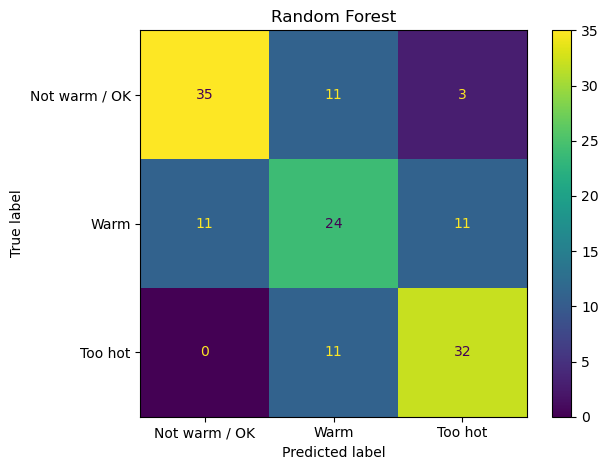

In [7]:
X_train = train_df[FEATURES].copy()
y_train = train_df["thermal_class_code"].astype(int).copy()

X_test = test_df[FEATURES].copy()
y_test = test_df["thermal_class_code"].astype(int).copy()

print("Features:")
print(FEATURES)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

fitted_models, cv_results = train_candidate_models(
    X_train,
    y_train,
)

print("\nTraining CV results:")
display(cv_results)

selected_model_name = cv_results.iloc[0]["model"]

print(
    "\nModel selected using training CV only:",
    selected_model_name,
)

test_metrics, test_outputs = evaluate_candidate_models(
    fitted_models,
    X_test,
    y_test,
)

print("\nHeld-out test metrics:")
display(test_metrics)

print_detailed_evaluation(
    selected_model_name,
    y_test,
    test_outputs[selected_model_name]["pred"],
)

In [ ]:
# Get the predictions from the model that was selected as best
# using training cross-validation.
selected_pred = test_outputs[selected_model_name]["pred"]

# Get the predicted probabilities from that same selected model.
selected_prob = test_outputs[selected_model_name]["prob"]


# Make a copy of the test set for evaluation.
test_eval = test_df.copy()

# Add the model's predicted class to the copied test data.
test_eval["prediction"] = selected_pred


# Create an empty list to store evaluation results for each city.
city_rows = []


# Loop through each unique city in the test set.
# sorted() puts the city names in order.
# dropna() removes missing city values.
# unique() gets each city only once.
for city in sorted(test_eval["city"].dropna().unique()):

    # Create a True/False mask for rows belonging to the current city.
    #
    # Example for Madrid:
    # [False, True, True, False, ...]
    mask = test_eval["city"].eq(city).to_numpy()

    # Calculate the evaluation metrics for only this city's rows.
    city_rows.append(
        metric_row(
            city,

            # True thermal classes for this city.
            y_test.to_numpy()[mask],

            # Predicted thermal classes for this city.
            selected_pred[mask],

            # Predicted class probabilities for this city.
            selected_prob[mask],
        )
    )


# Convert the list of city metric dictionaries into a DataFrame.
city_metrics = pd.DataFrame(city_rows)


# Show the selected model's performance separately for each city.
print("Selected-model performance by city:")
display(city_metrics)

Selected-model performance by city:


,model,macro_f1,balanced_accuracy,ordinal_mae,brier
0,Madrid,0.625641,0.631410,0.327869,0.430516
1,Warsaw,0.583917,0.574916,0.389610,0.487953


In [ ]:
# Define the file path where cross-validation results will be saved.
cv_output = RESULTS_DIR / "experiment_5_historical_weather_cv_results.csv"

# Define the file path where overall test metrics will be saved.
test_output = RESULTS_DIR / "experiment_5_historical_weather_test_metrics.csv"

# Define the file path where per-city metrics will be saved.
city_output = RESULTS_DIR / "experiment_5_historical_weather_city_metrics.csv"


# Save the cross-validation results to CSV.
cv_results.to_csv(cv_output, index=False)

# Save the held-out test results to CSV.
test_metrics.to_csv(test_output, index=False)

# Save the per-city evaluation results to CSV.
city_metrics.to_csv(city_output, index=False)


# Create a folder specifically for the Experiment 5 model artifact.
experiment_artifact_dir = ARTIFACTS_DIR / "experiment_5_historical_weather"

# Create the folder if it does not already exist.
# parents=True also creates missing parent folders.
# exist_ok=True prevents an error if the folder already exists.
experiment_artifact_dir.mkdir(parents=True, exist_ok=True)


# Get the model type and trained model object
# for the model selected as best by training cross-validation.
kind, selected_model = fitted_models[selected_model_name]


# Create one dictionary containing the trained model
# together with all important information needed later.
bundle = {

    # Name of this experiment.
    "experiment": "experiment_5_historical_weather",

    # Record how the final model was selected.
    "selected_by": "training_cv_macro_f1",

    # Store the name of the selected model.
    "selected_model_name": selected_model_name,

    # Store whether it is a sklearn model or ordinal model.
    "model_kind": kind,

    # Store the four input features expected by the model.
    "features": FEATURES,

    # Store the random seed used in the experiment.
    "random_state": RANDOM_STATE,

    # Store the proportion used for the test set.
    "test_size": TEST_SIZE,

    # Store the readable thermal class names.
    "class_names": CLASS_NAMES,

    # Store the actual trained model.
    "model": selected_model,
}


# Define where the final model bundle will be saved.
artifact_path = (
    experiment_artifact_dir
    / "selected_model.joblib"
)


# Save the whole bundle to a .joblib file.
# This is the file later loaded by predict.py.
joblib.dump(bundle, artifact_path)


# Print the saved file locations so we can confirm everything was created.
print("Saved CV results:", cv_output)
print("Saved test results:", test_output)
print("Saved city results:", city_output)
print("Saved selected model bundle:", artifact_path)

Saved CV results: ai/thermal_model\results\experiment_5_historical_weather_cv_results.csv
Saved test results: ai/thermal_model\results\experiment_5_historical_weather_test_metrics.csv
Saved city results: ai/thermal_model\results\experiment_5_historical_weather_city_metrics.csv
Saved selected model bundle: ai/thermal_model\artifacts\experiment_5_historical_weather\selected_model.joblib
